# Credit Score Classification

Predict a customer's credit score (Poor / Standard / Good) from their monthly bank and credit data.

Dataset: [Credit Score Classification](https://www.kaggle.com/datasets/parisrohan/credit-score-classification) on Kaggle.
train.csv has January to August for 12,500 customers, and test.csv has September to December for the same customers (no labels).

Since every customer has many monthly rows, a random train/validation split would leak information. So I evaluate in two ways:
- **A. New customers:** group k-fold on Customer_ID, so a customer is never in both train and validation.
- **B. Existing customers:** time split (train Jan-Jun, validate Jul-Aug), using each customer's past scores as features.

In [1]:
!pip install -q kagglehub lightgbm xgboost

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEED = 42
labels = {'Poor': 0, 'Standard': 1, 'Good': 2}
inv_labels = {v: k for k, v in labels.items()}

## 1. Load data

In [3]:
import kagglehub
path = kagglehub.dataset_download('parisrohan/credit-score-classification')

train_raw = pd.read_csv(os.path.join(path, 'train.csv'), low_memory=False)
test_raw = pd.read_csv(os.path.join(path, 'test.csv'), low_memory=False)
print(train_raw.shape, test_raw.shape)
train_raw.head()

100%|██████████| 9.51M/9.51M [00:00<00:00, 77.9MB/s]

Extracting files...


(100000, 28) (50000, 27)


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good


## 2. EDA

In [4]:
print('train months:', train_raw['Month'].unique())
print('test months:', test_raw['Month'].unique())
print('customers in train:', train_raw['Customer_ID'].nunique())
print('customers in both:', len(set(train_raw['Customer_ID']) & set(test_raw['Customer_ID'])))
train_raw.info()

train months: ['January' 'February' 'March' 'April' 'May' 'June' 'July' 'August']
test months: ['September' 'October' 'November' 'December']
customers in train: 12500
customers in both: 12500
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  object 
 1   Customer_ID               100000 non-null  object 
 2   Month                     100000 non-null  object 
 3   Name                      90015 non-null   object 
 4   Age                       100000 non-null  object 
 5   SSN                       100000 non-null  object 
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  object 
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card      

In [5]:
# missing values in %
(train_raw.isna().mean() * 100).round(2).sort_values(ascending=False).head(10)

,0
Monthly_Inhand_Salary,15.00
Type_of_Loan,11.41
Name,9.98
Credit_History_Age,9.03
Num_of_Delayed_Payment,7.00
Amount_invested_monthly,4.48
Num_Credit_Inquiries,1.96
Monthly_Balance,1.20
Month,0.00
Age,0.00


In [6]:
# many numeric columns are stored as text and have junk values
for col in ['Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
            'Outstanding_Debt', 'Amount_invested_monthly', 'Monthly_Balance']:
    s = train_raw[col].dropna().astype(str)
    bad = s[pd.to_numeric(s, errors='coerce').isna()]
    print(col, len(bad), bad.value_counts().head(3).index.tolist())

for col in ['Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']:
    print(train_raw[col].value_counts().head(8), '\n')

Age 4939 ['24_', '38_', '29_']
Annual_Income 6980 ['42904.26_', '14388.79_', '28381.96_']
Num_of_Loan 4785 ['2_', '4_', '3_']
Num_of_Delayed_Payment 2744 ['8_', '15_', '10_']
Changed_Credit_Limit 2091 ['_']
Outstanding_Debt 1009 ['396.97_', '881.24_', '188.33_']
Amount_invested_monthly 4305 ['__10000__']
Monthly_Balance 9 ['__-333333333333333333333333333__']
Occupation
_______       7062
Lawyer        6575
Architect     6355
Engineer      6350
Scientist     6299
Mechanic      6291
Accountant    6271
Developer     6235
Name: count, dtype: int64 

Credit_Mix
Standard    36479
Good        24337
_           20195
Bad         18989
Name: count, dtype: int64 

Payment_of_Min_Amount
Yes    52326
No     35667
NM     12007
Name: count, dtype: int64 

Payment_Behaviour
Low_spent_Small_value_payments      25513
High_spent_Medium_value_payments    17540
Low_spent_Medium_value_payments     13861
High_spent_Large_value_payments     13721
High_spent_Small_value_payments     11340
Low_spent_Large_valu

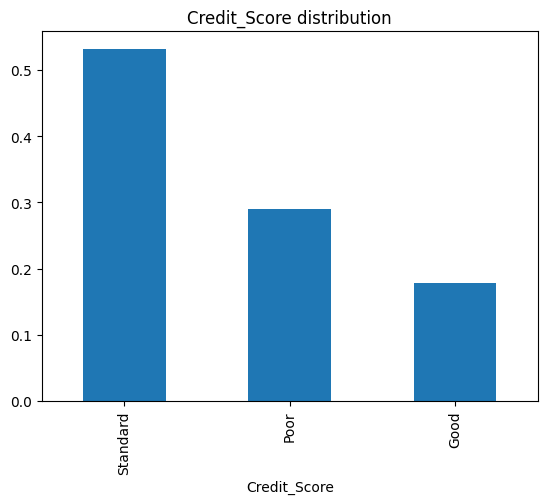

In [7]:
train_raw['Credit_Score'].value_counts(normalize=True).plot(kind='bar', title='Credit_Score distribution')
plt.show()

## 3. Data cleaning

Train and test have the same customers, so I clean them together (only features, labels are not used).
Each customer has 12 monthly rows, so a wrong value can be fixed using the same customer's other months.

In [8]:
train_raw['is_train'] = 1
test_raw['is_train'] = 0
df = pd.concat([train_raw, test_raw], ignore_index=True)

months = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August',
          'September', 'October', 'November', 'December']
df['Month_num'] = df['Month'].map({m: i + 1 for i, m in enumerate(months)})
df = df.sort_values(['Customer_ID', 'Month_num']).reset_index(drop=True)
cust = df['Customer_ID']

In [9]:
def to_num(s):
    s = s.astype(str).str.strip()
    s = s.mask(s.str.startswith('_', na=False))             # '_', '__10000__' etc are placeholders
    s = pd.to_numeric(s.str.rstrip('_'), errors='coerce')   # '45_' -> 45
    return s.mask(s.abs() > 1e12)


def customer_mode(s, cust):
    tmp = pd.DataFrame({'cust': cust.values, 'val': s.values}).dropna()
    modes = tmp.groupby('cust')['val'].agg(lambda x: x.value_counts().index[0])
    return cust.map(modes)


def fix_column(s, cust, lo=None, hi=None, abs_tol=None, rel_tol=None, fill='median'):
    if lo is not None:
        s = s.where(s >= lo)
    if hi is not None:
        s = s.where(s <= hi)
    # outlier = value too far from this customer's median
    if abs_tol is not None or rel_tol is not None:
        med = s.groupby(cust).transform('median')
        tol = np.maximum(abs_tol or 0, (rel_tol or 0) * med.abs())
        s = s.where((s - med).abs() <= tol)
    global_median = s.median()
    if fill == 'mode':
        s = s.fillna(customer_mode(s, cust))
    else:
        s = s.fillna(s.groupby(cust).transform('median'))
    return s.fillna(global_median)

In [10]:
num_cols = ['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card',
            'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment',
            'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio',
            'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance']
for col in num_cols:
    df[col] = to_num(df[col])

# these don't change for a customer -> use their most common value
df['Age'] = fix_column(df['Age'], cust, lo=10, hi=100, abs_tol=2, fill='mode')
df['Annual_Income'] = fix_column(df['Annual_Income'], cust, lo=0, rel_tol=0.25, fill='mode')
df['Num_Bank_Accounts'] = fix_column(df['Num_Bank_Accounts'], cust, lo=0, abs_tol=2, fill='mode')
df['Num_Credit_Card'] = fix_column(df['Num_Credit_Card'], cust, lo=0, abs_tol=2, fill='mode')
df['Interest_Rate'] = fix_column(df['Interest_Rate'], cust, lo=0, abs_tol=5, fill='mode')
df['Num_of_Loan'] = fix_column(df['Num_of_Loan'], cust, lo=0, abs_tol=2, fill='mode')

# these change month to month -> use the customer's median
df['Monthly_Inhand_Salary'] = fix_column(df['Monthly_Inhand_Salary'], cust, lo=0, rel_tol=0.25)
df['Num_of_Delayed_Payment'] = fix_column(df['Num_of_Delayed_Payment'], cust, lo=0, abs_tol=10)
df['Num_Credit_Inquiries'] = fix_column(df['Num_Credit_Inquiries'], cust, lo=0, abs_tol=10)
df['Total_EMI_per_month'] = fix_column(df['Total_EMI_per_month'], cust, lo=0, abs_tol=100, rel_tol=0.5)
df['Amount_invested_monthly'] = fix_column(df['Amount_invested_monthly'], cust, lo=0)
df['Outstanding_Debt'] = fix_column(df['Outstanding_Debt'], cust, lo=0)
for col in ['Changed_Credit_Limit', 'Monthly_Balance', 'Credit_Utilization_Ratio', 'Delay_from_due_date']:
    df[col] = fix_column(df[col], cust)

In [11]:
# categorical columns: '_', '_______', '!@9#%8' have no letters, 'NM' means not mentioned
for col in ['Occupation', 'Credit_Mix', 'Payment_Behaviour', 'Payment_of_Min_Amount']:
    s = df[col].where(df[col].astype(str).str.contains('[A-Za-z]', na=False))
    if col == 'Payment_of_Min_Amount':
        s = s.replace('NM', np.nan)
    df[col] = s.fillna(customer_mode(s, cust)).fillna('NM' if col == 'Payment_of_Min_Amount' else 'Unknown')

# '22 Years and 1 Months' -> 265 months. it goes up by 1 every month, so missing values can be filled exactly
ym = df['Credit_History_Age'].str.extract(r'(\d+) Years and (\d+) Months').astype(float)
hist = ym[0] * 12 + ym[1]
offset = (hist - df['Month_num']).groupby(cust).transform('median')
df['Credit_History_Months'] = hist.fillna(offset + df['Month_num']).fillna(hist.median())

df['Type_of_Loan'] = df['Type_of_Loan'].fillna('No Loan')

print('missing values left:', df[num_cols + ['Credit_History_Months']].isna().sum().sum())
df[num_cols + ['Credit_History_Months']].describe().T.round(2)

missing values left: 0


,count,mean,std,min,25%,50%,75%,max
Age,150000.0,33.48,10.77,14.00,25.00,33.00,42.00,56.00
Annual_Income,150000.0,50505.12,38299.36,7005.93,19342.97,36999.70,71683.47,179987.28
Monthly_Inhand_Salary,150000.0,4192.65,3182.84,303.65,1625.56,3091.00,5951.37,15204.63
Num_Bank_Accounts,150000.0,5.37,2.59,0.00,3.00,5.00,7.00,11.00
Num_Credit_Card,150000.0,5.53,2.07,0.00,4.00,5.00,7.00,11.00
Interest_Rate,150000.0,14.53,8.74,1.00,7.00,13.00,20.00,34.00
Num_of_Loan,150000.0,3.53,2.45,0.00,2.00,3.00,5.00,9.00
Delay_from_due_date,150000.0,21.06,14.86,-5.00,10.00,18.00,28.00,67.00
Num_of_Delayed_Payment,150000.0,13.33,6.27,0.00,9.00,14.00,18.00,28.00
Changed_Credit_Limit,150000.0,10.39,6.78,-6.49,5.34,9.40,14.83,36.97


## 4. Feature engineering

In [12]:
# Type_of_Loan is a list like "Auto Loan, Personal Loan, and Payday Loan" -> one count column per loan type
loan_lists = df['Type_of_Loan'].str.replace(r'\band\s+', '', regex=True).str.split(',')
loan_lists = loan_lists.apply(lambda l: [x.strip() for x in l if x.strip() and x.strip() != 'No Loan'])
loan_types = sorted({t for l in loan_lists for t in l})
loan_cols = []
for t in loan_types:
    name = 'Loan_' + t.replace(' ', '_').replace('-', '_')
    df[name] = loan_lists.apply(lambda l: l.count(t))
    loan_cols.append(name)

df['Debt_to_Income'] = df['Outstanding_Debt'] / (df['Annual_Income'] + 1)
df['EMI_to_Salary'] = df['Total_EMI_per_month'] / (df['Monthly_Inhand_Salary'] + 1)
df['Invest_to_Salary'] = df['Amount_invested_monthly'] / (df['Monthly_Inhand_Salary'] + 1)
df['Balance_to_Salary'] = df['Monthly_Balance'] / (df['Monthly_Inhand_Salary'] + 1)
df['Delay_Severity'] = df['Num_of_Delayed_Payment'] * df['Delay_from_due_date']
ratio_cols = ['Debt_to_Income', 'EMI_to_Salary', 'Invest_to_Salary', 'Balance_to_Salary', 'Delay_Severity']

In [13]:
# temporal features for the columns that change every month
dynamic_cols = ['Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries',
                'Credit_Utilization_Ratio', 'Amount_invested_monthly', 'Monthly_Balance', 'Outstanding_Debt']

g = df.groupby('Customer_ID')
month_c = df['Month_num'] - g['Month_num'].transform('mean')
temporal_cols = []

for col in dynamic_cols:
    lag1 = g[col].shift(1)
    lag2 = g[col].shift(2)
    mean = g[col].transform('mean')

    df[col + '_lag1'] = lag1.fillna(df[col])
    df[col + '_diff1'] = (df[col] - lag1).fillna(0)
    df[col + '_roll3'] = pd.concat([df[col], lag1, lag2], axis=1).mean(axis=1)
    df[col + '_cust_mean'] = mean
    df[col + '_cust_std'] = g[col].transform('std').fillna(0)
    df[col + '_cust_min'] = g[col].transform('min')
    df[col + '_cust_max'] = g[col].transform('max')
    df[col + '_dev'] = df[col] - mean
    # slope of the value over the months
    num = (month_c * (df[col] - mean)).groupby(df['Customer_ID']).transform('sum')
    den = (month_c ** 2).groupby(df['Customer_ID']).transform('sum')
    df[col + '_slope'] = (num / den).fillna(0)

    temporal_cols += [col + s for s in ['_lag1', '_diff1', '_roll3', '_cust_mean', '_cust_std',
                                        '_cust_min', '_cust_max', '_dev', '_slope']]

print(len(temporal_cols), 'temporal features')

72 temporal features


In [14]:
num_features = num_cols + ['Credit_History_Months'] + loan_cols + ratio_cols + temporal_cols
cat_features = ['Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']

train = df[df['is_train'] == 1].reset_index(drop=True)
test = df[df['is_train'] == 0].reset_index(drop=True)

X = train[num_features + cat_features]
X_test = test[num_features + cat_features]
y = train['Credit_Score'].map(labels)
groups = train['Customer_ID']
weights = compute_sample_weight('balanced', y)   # Standard is ~53% of rows
print(X.shape, X_test.shape)

(100000, 107) (50000, 107)


In [15]:
pd.crosstab(train['Credit_Mix'], train['Credit_Score'], normalize='index').round(3)

Credit_Score,Good,Poor,Standard
Credit_Mix,,,
Bad,0.015,0.601,0.384
Good,0.489,0.160,0.352
Standard,0.057,0.215,0.728


## 5. A: new customers (group k-fold)

All rows of a customer go to the same fold. Metric is macro F1 because the classes are imbalanced.

In [16]:
def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def make_prep(scale=False):
    if scale:
        num = Pipeline([('log', FunctionTransformer(signed_log1p, feature_names_out='one-to-one')),
                        ('scale', StandardScaler())])
    else:
        num = 'passthrough'
    return ColumnTransformer([('num', num, num_features),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)],
                             verbose_feature_names_out=False)


models = {
    'Logistic Regression': Pipeline([('prep', make_prep(scale=True)),
                                     ('clf', LogisticRegression(max_iter=3000))]),
    'Random Forest': Pipeline([('prep', make_prep()),
                               ('clf', RandomForestClassifier(n_estimators=250, min_samples_leaf=2,
                                                              n_jobs=-1, random_state=SEED))]),
    'XGBoost': Pipeline([('prep', make_prep()),
                         ('clf', XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=7,
                                               subsample=0.8, colsample_bytree=0.8, tree_method='hist',
                                               eval_metric='mlogloss', n_jobs=-1, random_state=SEED))]),
    'LightGBM': Pipeline([('prep', make_prep()),
                          ('clf', LGBMClassifier(n_estimators=600, learning_rate=0.05, num_leaves=63,
                                                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                                 n_jobs=-1, random_state=SEED, verbose=-1))]),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X, y, groups))

In [17]:
def run_cv(model, folds):
    oof = np.zeros((len(X), 3))
    scores = []
    for tr, va in folds:
        m = clone(model)
        m.fit(X.iloc[tr], y.iloc[tr], clf__sample_weight=weights[tr])
        oof[va] = m.predict_proba(X.iloc[va])
        scores.append(f1_score(y.iloc[va], oof[va].argmax(1), average='macro'))
    return oof, np.std(scores)


results = []
oof_preds = {}
for name, model in models.items():
    oof, std = run_cv(model, folds)
    pred = oof.argmax(1)
    oof_preds[name] = pred
    results.append([name, accuracy_score(y, pred), f1_score(y, pred, average='macro'), std])
    print(f'{name}: accuracy {results[-1][1]:.4f}, macro F1 {results[-1][2]:.4f} (+/- {std:.4f})')

results = pd.DataFrame(results, columns=['model', 'accuracy', 'macro_f1', 'f1_std'])
results = results.sort_values('macro_f1', ascending=False).reset_index(drop=True)
results

Logistic Regression: accuracy 0.6600, macro F1 0.6542 (+/- 0.0052)
Random Forest: accuracy 0.7067, macro F1 0.6884 (+/- 0.0063)
XGBoost: accuracy 0.6993, macro F1 0.6899 (+/- 0.0077)
LightGBM: accuracy 0.7002, macro F1 0.6885 (+/- 0.0057)


,model,accuracy,macro_f1,f1_std
0,XGBoost,0.69926,0.689935,0.007737
1,LightGBM,0.70020,0.688536,0.005690
2,Random Forest,0.70675,0.688419,0.006255
3,Logistic Regression,0.66001,0.654186,0.005179


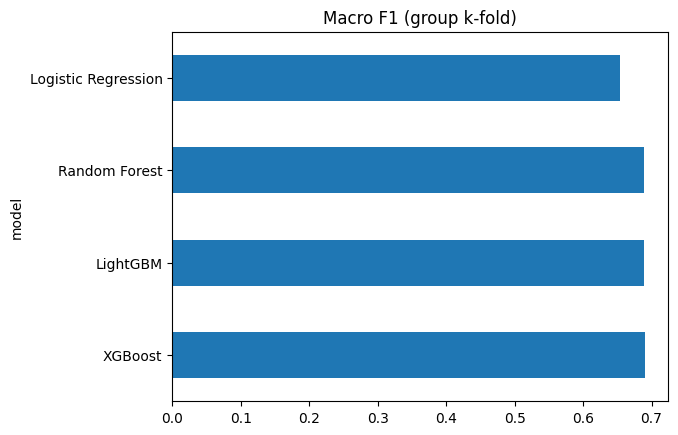

best model: XGBoost
              precision    recall  f1-score   support

        Poor     0.6878    0.7209    0.7040     28998
    Standard     0.8073    0.6529    0.7219     53174
        Good     0.5377    0.8024    0.6439     17828

    accuracy                         0.6993    100000
   macro avg     0.6776    0.7254    0.6899    100000
weighted avg     0.7246    0.6993    0.7028    100000



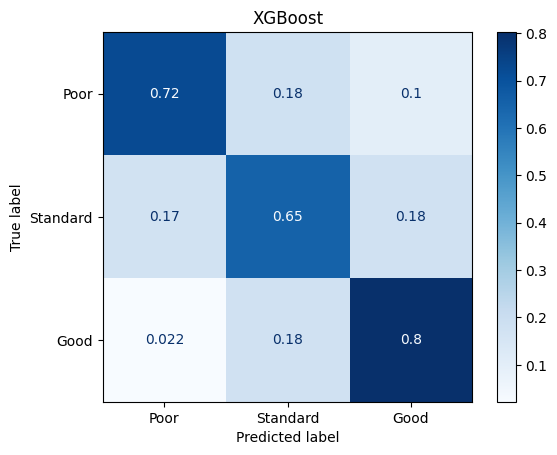

In [18]:
results.plot(x='model', y='macro_f1', kind='barh', legend=False, title='Macro F1 (group k-fold)')
plt.show()

best = results.loc[0, 'model']
print('best model:', best)
print(classification_report(y, oof_preds[best], target_names=list(labels), digits=4))

ConfusionMatrixDisplay(confusion_matrix(y, oof_preds[best], normalize='true'), display_labels=list(labels)).plot(cmap='Blues')
plt.title(best)
plt.show()

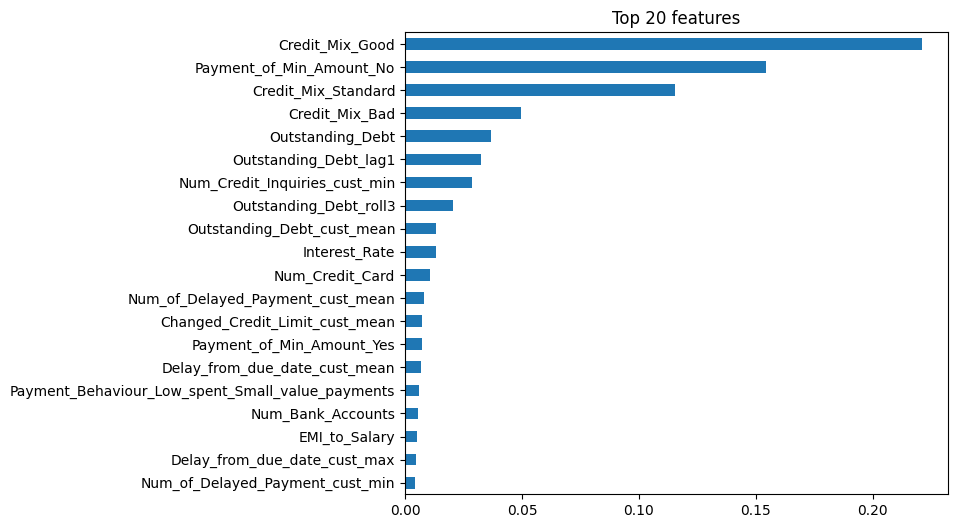

In [19]:
# train the best model on all training data
final_model = clone(models[best])
final_model.fit(X, y, clf__sample_weight=weights)

clf = final_model.named_steps['clf']
names = final_model.named_steps['prep'].get_feature_names_out()
imp = clf.feature_importances_ if hasattr(clf, 'feature_importances_') else np.abs(clf.coef_).mean(axis=0)
pd.Series(imp, index=names).sort_values().tail(20).plot(kind='barh', figsize=(7, 6), title='Top 20 features')
plt.show()

### Random split vs group split

With a random split, other months of the same customer end up in training, so the score looks much better than it really is.

In [20]:
random_folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y))
oof_random, _ = run_cv(models[best], random_folds)
random_acc = accuracy_score(y, oof_random.argmax(1))
random_f1 = f1_score(y, oof_random.argmax(1), average='macro')
print(f'random split: macro F1 {random_f1:.4f}, group split: macro F1 {results.loc[0, "macro_f1"]:.4f}')

random split: macro F1 0.7977, group split: macro F1 0.6899


In [21]:
test_pred = final_model.predict(X_test)
submission = pd.DataFrame({'ID': test['ID'], 'Customer_ID': test['Customer_ID'], 'Month': test['Month'],
                           'Credit_Score': pd.Series(test_pred).map(inv_labels)})
submission.to_csv('submission.csv', index=False)
joblib.dump(final_model, 'model_new_customers.joblib')
submission['Credit_Score'].value_counts(normalize=True)

,proportion
Credit_Score,
Standard,0.4195
Poor,0.3354
Good,0.2451


## 6. B: existing customers (time split)

This matches the test set: we know a customer's scores up to now and predict the next months.
- train on Jan-Jun, validate on Jul-Aug using only scores known up to June
- score history features: last score, previous score, mean score, share of Poor/Good months, number of changes
- test needs 1-4 months ahead, so each training month is used with cutoffs 1-4 months earlier (`horizon` feature)
- customer-wide features (`_cust_*`, `_dev`, `_slope`) use future months, so they are dropped here
- no class weights here, I care about accuracy for this one

In [22]:
fc_num = [c for c in num_features if not any(s in c for s in ['_cust_', '_dev', '_slope'])]
hist_features = ['last_score', 'prev_score', 'score_mean', 'frac_poor', 'frac_good', 'n_changes', 'n_known', 'horizon']

# customers x months table of scores
scores = train.assign(score=y.values).pivot(index='Customer_ID', columns='Month_num', values='score')


def history_features(K):
    # only months 1..K are known
    h = scores.loc[:, 1:K]
    out = pd.DataFrame(index=scores.index)
    out['last_score'] = h[K]
    out['prev_score'] = h[K - 1] if K > 1 else h[K]
    out['score_mean'] = h.mean(axis=1)
    out['frac_poor'] = (h == 0).mean(axis=1)
    out['frac_good'] = (h == 2).mean(axis=1)
    out['n_changes'] = (h.diff(axis=1).iloc[:, 1:] != 0).sum(axis=1)
    out['n_known'] = K
    return out


hist = {K: history_features(K) for K in range(1, 9)}


def make_examples(data, month_list, get_cutoffs):
    parts = []
    for m in month_list:
        rows = data[data['Month_num'] == m]
        for K in get_cutoffs(m):
            p = rows.join(hist[K], on='Customer_ID')
            p['horizon'] = m - K
            parts.append(p)
    return pd.concat(parts, ignore_index=True)


cutoffs = lambda m: list(range(max(1, m - 4), m))
fc_train = make_examples(train, range(2, 7), cutoffs)
fc_val = make_examples(train, [7, 8], lambda m: [6])
print(fc_train.shape, fc_val.shape)

(175000, 125) (25000, 125)


In [23]:
def make_lgbm(features):
    prep = ColumnTransformer([('num', 'passthrough', features),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)],
                             verbose_feature_names_out=False)
    return Pipeline([('prep', prep),
                     ('clf', LGBMClassifier(n_estimators=800, learning_rate=0.03, num_leaves=63,
                                            subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                            n_jobs=-1, random_state=SEED, verbose=-1))])


y_val = fc_val['Credit_Score'].map(labels)
fc_preds = {}

# baseline: just repeat the last known score
fc_preds['Baseline (last score)'] = fc_val['last_score'].astype(int).values

# lightgbm without score history
jan_jun = train[train['Month_num'] <= 6]
m1 = make_lgbm(fc_num).fit(jan_jun[fc_num + cat_features], jan_jun['Credit_Score'].map(labels))
fc_preds['LightGBM (features only)'] = m1.predict(fc_val[fc_num + cat_features])

# lightgbm with score history
fc_features = fc_num + hist_features
m2 = make_lgbm(fc_features).fit(fc_train[fc_features + cat_features], fc_train['Credit_Score'].map(labels))
fc_preds['LightGBM (+ score history)'] = m2.predict(fc_val[fc_features + cat_features])

fc_results = []
for name, p in fc_preds.items():
    h1 = (fc_val['horizon'] == 1).values
    fc_results.append([name, accuracy_score(y_val, p), f1_score(y_val, p, average='macro'),
                       accuracy_score(y_val[h1], p[h1]), accuracy_score(y_val[~h1], p[~h1])])
fc_results = pd.DataFrame(fc_results, columns=['model', 'accuracy', 'macro_f1', 'acc_1_month', 'acc_2_months'])
fc_results

,model,accuracy,macro_f1,acc_1_month,acc_2_months
0,Baseline (last score),0.72864,0.722093,0.72728,0.73000
1,LightGBM (features only),0.71552,0.706076,0.71392,0.71712
2,LightGBM (+ score history),0.75652,0.755943,0.75632,0.75672


              precision    recall  f1-score   support

        Poor     0.7231    0.8535    0.7829      7216
    Standard     0.8091    0.6942    0.7473     12960
        Good     0.7007    0.7788    0.7377      4824

    accuracy                         0.7565     25000
   macro avg     0.7443    0.7755    0.7559     25000
weighted avg     0.7633    0.7565    0.7557     25000



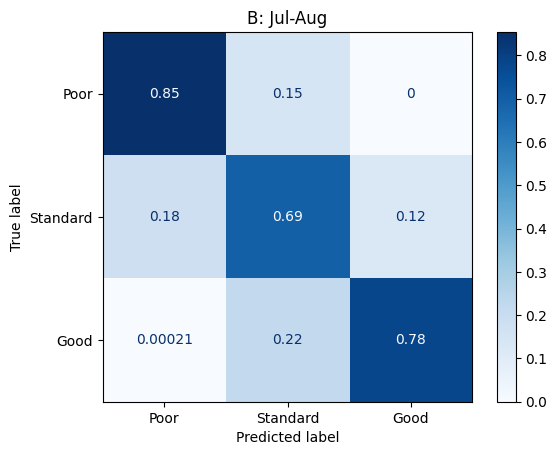

In [24]:
best_fc = fc_preds['LightGBM (+ score history)']
print(classification_report(y_val, best_fc, target_names=list(labels), digits=4))
ConfusionMatrixDisplay(confusion_matrix(y_val, best_fc, normalize='true'), display_labels=list(labels)).plot(cmap='Blues')
plt.title('B: Jul-Aug')
plt.show()

In [25]:
# final model: Feb-Aug for training, predict Sep-Dec using scores up to August
fc_full = make_examples(train, range(2, 9), cutoffs)
fc_test = make_examples(test, range(9, 13), lambda m: [8])
final_fc = make_lgbm(fc_features).fit(fc_full[fc_features + cat_features], fc_full['Credit_Score'].map(labels))

fc_sub = pd.DataFrame({'ID': fc_test['ID'], 'Customer_ID': fc_test['Customer_ID'], 'Month': fc_test['Month'],
                       'Credit_Score': pd.Series(final_fc.predict(fc_test[fc_features + cat_features])).map(inv_labels)})
fc_sub.to_csv('submission_forecast.csv', index=False)
joblib.dump(final_fc, 'model_existing_customers.joblib')
fc_sub['Credit_Score'].value_counts(normalize=True)

,proportion
Credit_Score,
Standard,0.48410
Poor,0.31692
Good,0.19898


## 7. Summary

In [26]:
r = fc_results.set_index('model')
summary = pd.DataFrame([
    ['Random split (leaky)', random_acc, random_f1],
    ['A: new customers (group k-fold)', results.loc[0, 'accuracy'], results.loc[0, 'macro_f1']],
    ['B: baseline, repeat last score', r.loc['Baseline (last score)', 'accuracy'], r.loc['Baseline (last score)', 'macro_f1']],
    ['B: features only', r.loc['LightGBM (features only)', 'accuracy'], r.loc['LightGBM (features only)', 'macro_f1']],
    ['B: + score history', r.loc['LightGBM (+ score history)', 'accuracy'], r.loc['LightGBM (+ score history)', 'macro_f1']],
], columns=['setup', 'accuracy', 'macro_f1'])
summary.round(4)

,setup,accuracy,macro_f1
0,Random split (leaky),0.8021,0.7977
1,A: new customers (group k-fold),0.6993,0.6899
2,"B: baseline, repeat last score",0.7286,0.7221
3,B: features only,0.7155,0.7061
4,B: + score history,0.7565,0.7559


**Notes**
- The random split gives ~80% accuracy but it leaks: the same customers are in train and validation.
- For new customers the honest accuracy is ~70%. Temporal features helped only a little.
- For existing customers, past scores help a lot: 75.7% accuracy vs 72.9% for just repeating the last score.
- About 27% of customers change score from one month to the next, which limits how high accuracy can go.